# Latent Semantic Analysis (LSA)

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/02-05-SVD-Latent-Semantic-Analysis-Example.ipynb)

The goal of Latent Semantic Analysis (LSA) is to reduce the number of features (tokens) in a document-term matrix while preserving the similarity structure among documents. This is achieved by transforming the high-dimensional term space into a low-dimensional space with the Singular Value Decomposition (SVD), see the [SVD chapter](02-04-SVD.ipynb).

For a document-term matrix $A$ with $n$ documents (rows) and $m$ terms (columns) the SVD is

:::{.ex-class}
$$
A = U \Sigma V^\top
$$
:::

- the columns of $V$ ($m \times r$) are the **term loadings** of the components: they show which terms make up a component,
- the diagonal of $\Sigma$ holds the **singular values**: $\sigma_k^2$ is the part of the total sum of squares $\sum_{ij} a_{ij}^2 = \sum_k \sigma_k^2$ that component $k$ accounts for,
- the rows of $U \Sigma = A V$ are the **document coordinates** (scores) in the space of the components.

We apply LSA twice to the same TF-IDF matrix: once to the matrix as it is (this is what `sklearn.decomposition.TruncatedSVD` does) and once to the column-centered matrix $A - \mathbf{1}\bar{a}^\top$ (this is PCA). The comparison shows what centering changes in the components and in the separation of the documents.

In [1]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objs as go

from nltk.corpus import reuters
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score

nltk.download('reuters', quiet=True)

True

## Data

We use three categories of the Reuters corpus (distributed with NLTK): gasoline (`gas`), consumer prices (`cpi`) and `coffee`. Every file is one news article. A few articles carry more than one of the three labels; we drop them so that every document has exactly one topic.

In [2]:
categories = ["gas", "cpi", "coffee"]

fileids_by_topic = {topic: set(reuters.fileids([topic])) for topic in categories}

texts = []
topics = []
for topic in categories:
    # keep only the articles that belong to exactly one of the three categories
    single_label = sorted(
        fileid for fileid in fileids_by_topic[topic]
        if sum(fileid in fileids for fileids in fileids_by_topic.values()) == 1
    )
    texts += [reuters.raw(fileid) for fileid in single_label]
    topics += [topic] * len(single_label)

topics = np.array(topics)
print(pd.Series(topics).value_counts())

coffee    139
cpi        96
gas        53
Name: count, dtype: int64


In [3]:
# no-ex-class
# The beginning of the first article of each topic
for topic in categories:
    print(f"--- {topic} ---")
    first_text = texts[list(topics).index(topic)]
    print("\n".join(first_text.split("\n")[:6]))

--- gas ---
FINNS AND CANADIANS TO STUDY MTBE PRODUCTION PLANT
  Finland's national oil company Neste Oy
  &lt;NEOY.HE> said in a statement it had agreed with Canadian firms
  to study the feasibility of building a plant in Edmonton,
  Canada, to produce a replacement for lead in petrol.
      The prospective plant would cost an estimated 270 mln
--- cpi ---
ECONOMIC SPOTLIGHT - KUWAITI ECONOMY
  Kuwait's oil-reliant and debt-ridden
  economy has started to pull out of a nosedive but oil prices
  will determine the pace of recovery, bankers and economists
  say.
      Crucial will be the ability of the 13-member OPEC to hold
--- coffee ---
INDONESIAN COMMODITY EXCHANGE MAY EXPAND
  The Indonesian Commodity Exchange is
  likely to start trading in at least one new commodity, and
  possibly two, during calendar 1987, exchange chairman Paian
  Nainggolan said.
      He told Reuters in a telephone interview that trading in


## The TF-IDF Matrix

We remove the numbers because they occur in almost every article and obscure the results, drop English stop words and keep only terms that occur in at least 5% of the documents.

In [4]:
texts = [re.sub(r"\d+", "", text) for text in texts]

tfidf = TfidfVectorizer(lowercase=True, stop_words="english", min_df=0.05)
term_doc_matrix = tfidf.fit_transform(texts).toarray()   # n documents x m terms, rows have unit length
terms = np.array(tfidf.get_feature_names_out())

print("Shape (documents x terms):", term_doc_matrix.shape)
print("Most important terms (column sums):")
print(pd.Series(term_doc_matrix.sum(axis=0), index=terms).sort_values(ascending=False).head(10).round(1))

Shape (documents x terms): (288, 292)
Most important terms (column sums):
pct          40.7
coffee       34.2
said         31.6
year         23.0
mln          22.1
february     17.9
prices       16.7
inflation    15.3
january      12.9
ico          12.8
dtype: float64


## Helper Functions

`lsa_svd()` computes the SVD of a matrix (the matrices are small, so we use the full dense SVD). The sign of a singular vector pair $(u_k, v_k)$ is arbitrary, so we fix it by making the term with the largest absolute loading positive. The other helpers produce the same tables and figures for both analyses.

In [5]:
def lsa_svd(matrix):
    """SVD of a matrix: document scores (U * Sigma), singular values and the term loadings (rows of Vt)."""
    U, sigma, Vt = np.linalg.svd(matrix, full_matrices=False)
    # fix the arbitrary sign: the largest absolute loading of every component is positive
    signs = np.sign(Vt[np.arange(len(sigma)), np.abs(Vt).argmax(axis=1)])
    return {"scores": (U * sigma) * signs, "sigma": sigma, "Vt": Vt * signs[:, None],
            "share": sigma**2 / np.sum(sigma**2)}


def plot_scree(result, title, n_show=15):
    share = result["share"][:n_show]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(np.arange(1, n_show + 1), share)
    ax.plot(np.arange(1, n_show + 1), np.cumsum(share), "o-", color="black", label="cumulative")
    ax.set_xlabel("Component")
    ax.set_ylabel("Share of the sum of squares")
    ax.set_title(title)
    ax.legend()
    plt.show()


def top_terms(result, n_terms=8, n_components=3):
    """Terms with the most positive and the most negative loadings of the first components."""
    table = {}
    for k in range(n_components):
        order = np.argsort(result["Vt"][k])
        table[f"PC{k + 1} (+)"] = [f"{terms[i]} ({result['Vt'][k, i]:.2f})" for i in order[::-1][:n_terms]]
        table[f"PC{k + 1} (-)"] = [f"{terms[i]} ({result['Vt'][k, i]:.2f})" for i in order[:n_terms]]
    return pd.DataFrame(table)


topic_colors = {"gas": "#EF553B", "cpi": "#636EFA", "coffee": "#00CC96"}


def plot_documents_3d(result, title):
    scores, share = result["scores"], result["share"]
    fig = go.Figure()
    for topic in categories:
        mask = topics == topic
        fig.add_trace(go.Scatter3d(
            x=scores[mask, 0], y=scores[mask, 1], z=scores[mask, 2], mode="markers", name=topic,
            marker=dict(size=4, color=topic_colors[topic], opacity=0.8, line=dict(width=0.5, color="black"))))
    fig.update_layout(
        title=title, width=800, height=700,
        scene=dict(xaxis_title=f"PC1 ({share[0]:.0%})", yaxis_title=f"PC2 ({share[1]:.0%})",
                   zaxis_title=f"PC3 ({share[2]:.0%})"),
        legend=dict(itemsizing="constant"))
    fig.show()


def plot_documents_2d(result, title):
    scores, share = result["scores"], result["share"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
        for topic in categories:
            mask = topics == topic
            ax.scatter(scores[mask, i], scores[mask, j], s=12, alpha=0.7, color=topic_colors[topic], label=topic)
        ax.set_xlabel(f"PC{i + 1} ({share[i]:.0%})")
        ax.set_ylabel(f"PC{j + 1} ({share[j]:.0%})")
    axes[0].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Analysis A: SVD of the Raw TF-IDF Matrix

This is the decomposition of $A$ itself, which is also what `TruncatedSVD` computes (it never centers the data, because centering would destroy the sparsity of large document-term matrices).

In [6]:
raw = lsa_svd(term_doc_matrix)

# TruncatedSVD gives the same singular values
truncated = TruncatedSVD(n_components=3, n_iter=100, random_state=42).fit(term_doc_matrix)
print("TruncatedSVD equals the SVD of A:", np.allclose(truncated.singular_values_, raw["sigma"][:3]))

mean_document = term_doc_matrix.mean(axis=0)
cosine_with_mean = raw["Vt"][0] @ mean_document / np.linalg.norm(mean_document)
print("All loadings of PC1 positive:", bool((raw["Vt"][0] > 0).all()))
print("Cosine between the first right singular vector and the mean document:", round(float(cosine_with_mean), 3))
print("Share of the sum of squares of the first three components:", raw["share"][:3].round(3))

TruncatedSVD equals the SVD of A: True
All loadings of PC1 positive: True
Cosine between the first right singular vector and the mean document: 0.981
Share of the sum of squares of the first three components: [0.152 0.094 0.051]


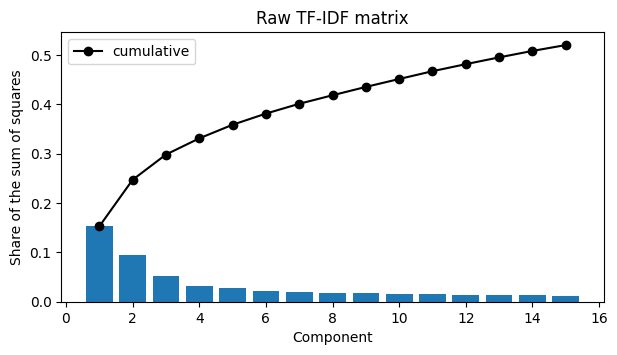

In [7]:
plot_scree(raw, "Raw TF-IDF matrix")

In [8]:
top_terms(raw)

,PC1 (+),PC1 (-),PC2 (+),PC2 (-),PC3 (+),PC3 (-)
0,pct (0.47),held (0.01),pct (0.43),coffee (-0.42),mln (0.65),ico (-0.14)
1,coffee (0.27),weekly (0.01),february (0.23),ico (-0.20),gasoline (0.30),quotas (-0.13)
2,said (0.27),administration (0.01),january (0.17),quotas (-0.19),crude (0.27),coffee (-0.13)
3,year (0.24),estimate (0.01),inflation (0.16),export (-0.17),stocks (0.21),february (-0.12)
4,february (0.22),close (0.01),rise (0.12),brazil (-0.15),distillate (0.20),meeting (-0.10)
5,inflation (0.17),prospects (0.01),rose (0.12),meeting (-0.14),says (0.20),delegates (-0.09)
6,prices (0.16),capital (0.01),index (0.12),said (-0.14),barrels (0.20),producers (-0.08)
7,mln (0.16),does (0.01),year (0.11),producers (-0.13),oil (0.14),consumer (-0.07)


In [9]:
plot_documents_3d(raw, "Documents in the space of the first three components (raw)")

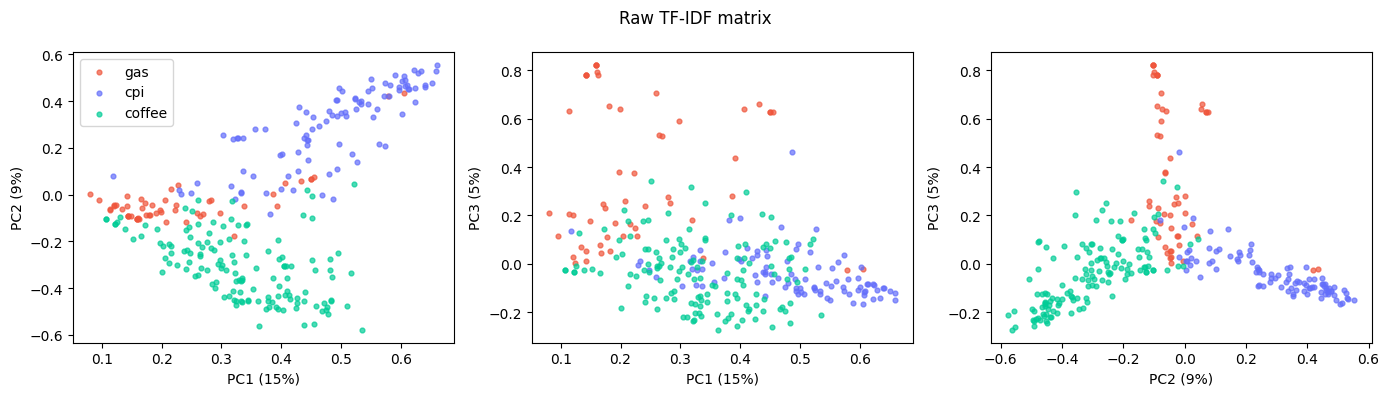

In [10]:
# no-ex-class
plot_documents_2d(raw, "Raw TF-IDF matrix")

### Interpretation (raw)

- **PC1 is not a topic, it is the "average document".** All term loadings of the first component are positive and the component is almost parallel to the mean document (cosine 0.98). Its largest loadings are the terms that are frequent across all three topics (`pct`, `coffee`, `said`, `year`, `february`). Because TF-IDF values are non-negative, the first singular vector of a raw matrix always points roughly towards the mean, and it accounts for the largest part of the sum of squares (15.2%) mainly for this reason. The scores on PC1 are positive for all documents (topic means 0.23 for `gas`, 0.33 for `coffee`, 0.48 for `cpi`, standard deviation 0.14), so they describe how much a document resembles the typical article, not what it is about. In the 3-D figure the whole cloud therefore lies away from the origin along PC1.
- **PC2 separates `cpi` from `coffee`.** Terms with positive loadings (`pct`, `february`, `january`, `inflation`, `rise`, `index`) describe price statistics, terms with negative loadings (`coffee`, `ico`, `quotas`, `export`, `brazil`, `meeting`) describe the coffee market and the agreements of the International Coffee Organization. The topic means on PC2 are 0.29 (`cpi`), -0.30 (`coffee`) and -0.03 (`gas`).
- **PC3 separates `gas` from the other two topics.** Positive loadings: `mln`, `gasoline`, `crude`, `stocks`, `distillate`, `barrels`, `oil`; the topic means are 0.36 for `gas` and -0.04 for both other topics.
- **Separation.** In the plane of PC1 and PC2 the `gas` documents lie between the other two groups and overlap with them; only PC3 pulls them apart (silhouette score 0.33 with two components and 0.44 with three, cross-validated LDA accuracy 0.86 and 0.90, see the comparison below). The sign of a component is arbitrary; we fixed it so that the term with the largest absolute loading is positive.

## Analysis B: SVD of the Centered TF-IDF Matrix

Now we subtract the mean of every column (the mean document) from the matrix and decompose

:::{.ex-class}
$$
A - \mathbf{1} \bar{a}^\top = U \Sigma V^\top
$$
:::

The squared singular values are now proportional to the variances along the components, and $V$ contains the principal axes. This is PCA, and the document coordinates are the principal component scores.

In [11]:
centered_matrix = term_doc_matrix - term_doc_matrix.mean(axis=0)
centered = lsa_svd(centered_matrix)

pca = PCA(n_components=3).fit(term_doc_matrix)
print("PCA equals the SVD of the centered matrix:", np.allclose(pca.singular_values_, centered["sigma"][:3]))
print("Share of the sum of squares of the first three components:", centered["share"][:3].round(3))

PCA equals the SVD of the centered matrix: True
Share of the sum of squares of the first three components: [0.112 0.063 0.038]


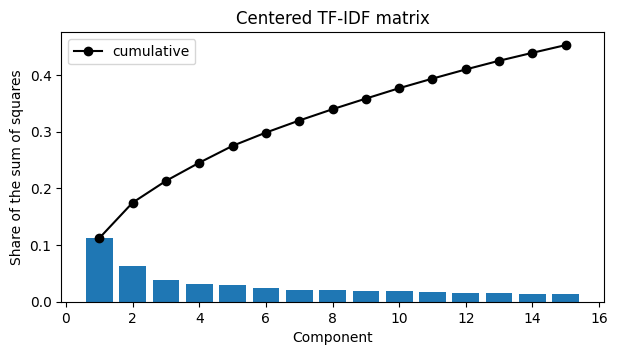

In [12]:
plot_scree(centered, "Centered TF-IDF matrix")

In [13]:
top_terms(centered)

,PC1 (+),PC1 (-),PC2 (+),PC2 (-),PC3 (+),PC3 (-)
0,pct (0.54),coffee (-0.33),mln (0.53),coffee (-0.25),mln (0.33),billion (-0.20)
1,february (0.29),ico (-0.16),gasoline (0.29),ico (-0.19),february (0.22),growth (-0.20)
2,inflation (0.20),quotas (-0.15),crude (0.24),quotas (-0.18),ico (0.20),economic (-0.19)
3,january (0.20),export (-0.13),stocks (0.18),february (-0.15),quotas (0.16),state (-0.16)
4,year (0.17),meeting (-0.12),says (0.18),pct (-0.15),stocks (0.14),dlrs (-0.13)
5,rise (0.15),brazil (-0.11),distillate (0.18),meeting (-0.14),crude (0.14),government (-0.13)
6,rose (0.15),producers (-0.10),barrels (0.17),producers (-0.12),january (0.14),deficit (-0.12)
7,index (0.14),talks (-0.09),oil (0.13),delegates (-0.11),distillate (0.14),economy (-0.12)


In [14]:
plot_documents_3d(centered, "Documents in the space of the first three components (centered)")

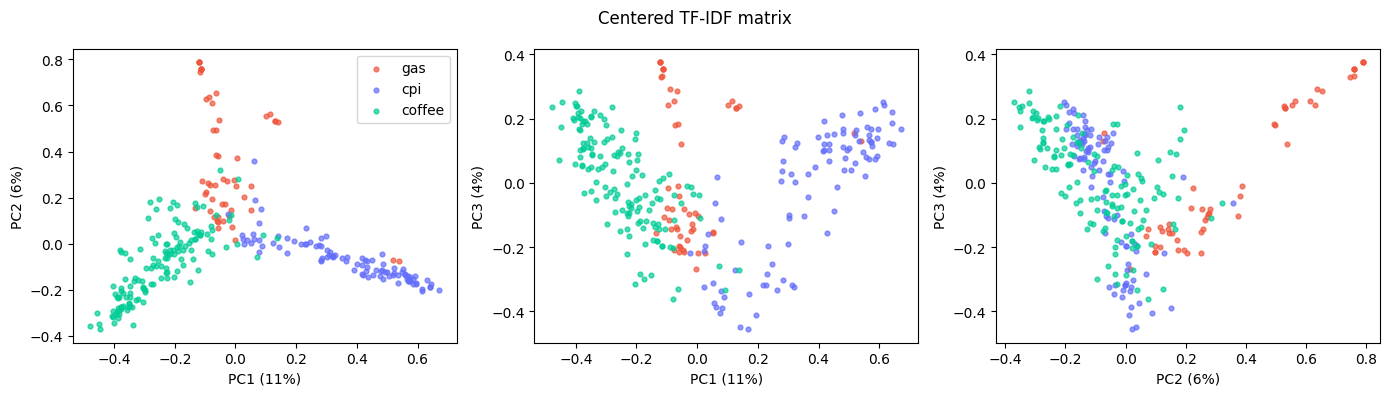

In [15]:
# no-ex-class
plot_documents_2d(centered, "Centered TF-IDF matrix")

### Interpretation (centered)

- **There is no "average document" component anymore.** After subtracting the mean document, the components describe how documents *differ* from the average one. The sum of squares to be explained is smaller, and the first three components account for 21.3% of it (11.2%, 6.3% and 3.8%).
- **PC1 separates `cpi` from `coffee`** (it corresponds to PC2 of the raw analysis): positive loadings for `pct`, `february`, `inflation`, `january`, `rise`, `index`, negative ones for `coffee`, `ico`, `quotas`, `export`, `meeting`, `brazil`. Topic means: 0.37 (`cpi`), -0.25 (`coffee`), -0.02 (`gas`).
- **PC2 separates `gas` from the rest** (`mln`, `gasoline`, `crude`, `stocks`, `distillate`, `barrels`, `oil` against `coffee`, `ico`, `quotas`): topic means 0.36 (`gas`), -0.07 (`cpi`) and -0.09 (`coffee`).
- **PC3 does not separate the topics** (all three topic means are within 0.03 of zero). It contrasts macro-economic vocabulary (`billion`, `growth`, `economic`, `government`, `deficit`, `economy`) with commodity-market statistics (`mln`, `stocks`, `ico`, `quotas`, `crude`), i.e. variation *within* the topics. The third dimension therefore adds hardly anything to the separation (silhouette 0.48 with two components, 0.40 with three; LDA accuracy 0.88 and 0.90).
- Two components are enough to see the three topics in the plane (PC1, PC2) of the centered analysis.
- In the plane of PC1 and PC2 the documents form three arms that start near the origin (articles with a mixed vocabulary) and point to the pure `coffee`, `cpi` and `gas` articles; the overlap between the topics is limited to the region near the origin.

## Comparison

First, how are the components of the two analyses related? The matrix below shows the absolute cosine similarity between the term loadings (right singular vectors) of the raw (rows) and the centered (columns) analysis.

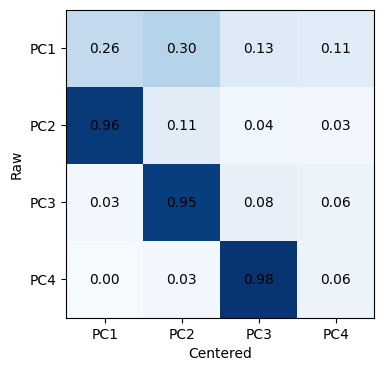

In [16]:
similarity = np.abs(raw["Vt"][:4] @ centered["Vt"][:4].T)

fig, ax = plt.subplots(figsize=(4.5, 4))
image = ax.imshow(similarity, vmin=0, vmax=1, cmap="Blues")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center")
ax.set_xticks(range(4), [f"PC{j + 1}" for j in range(4)])
ax.set_yticks(range(4), [f"PC{i + 1}" for i in range(4)])
ax.set_xlabel("Centered")
ax.set_ylabel("Raw")
plt.show()

Second, how well do the first two or three components separate the topics? We use the silhouette score (high values mean compact and well separated groups) and the cross-validated accuracy of a linear discriminant analysis. The topic labels are not used to compute the components, only to evaluate them.

In [17]:
rows = []
for name, result in [("raw", raw), ("centered", centered)]:
    for n_dims in (2, 3):
        coordinates = result["scores"][:, :n_dims]
        rows.append({
            "analysis": name,
            "components": n_dims,
            "silhouette": silhouette_score(coordinates, topics),
            "LDA accuracy": cross_val_score(LinearDiscriminantAnalysis(), coordinates, topics, cv=5).mean(),
        })

pd.DataFrame(rows).round(3)

,analysis,components,silhouette,LDA accuracy
0,raw,2,0.333,0.858
1,raw,3,0.441,0.903
2,centered,2,0.477,0.882
3,centered,3,0.403,0.903


### Discussion

- **Centering removes the mean direction.** The cosine matrix shows that PC2, PC3 and PC4 of the raw analysis are almost the same directions as PC1, PC2 and PC3 of the centered one (cosines 0.96, 0.95 and 0.98), while PC1 of the raw analysis has no counterpart (all cosines at most 0.30). The raw decomposition spends its first component on the mean document and shifts all topical components by one position. In the 2-D figures the cloud is shifted away from the origin in the raw analysis, while it is centered at the origin in the centered one.
- **What this means for three components.** With centering all three components describe differences between documents, but the third one is not topical. Without centering the first component is "wasted" on the average document, but the three components still contain both topical dimensions, and PC1 itself carries a little topical information (`cpi` articles have the largest scores). The silhouette score in 3-D is 0.44 for the raw and 0.40 for the centered analysis, a small difference that we would not over-interpret. The cross-validated accuracy of a linear classifier is the same (0.90) for both.
- **Which one to use?** To study how documents differ from each other, to interpret the first components as topics and to compare the explained variance, center the data (PCA). `TruncatedSVD` skips the centering because subtracting the mean makes a large sparse document-term matrix dense; with raw LSA the first component should be recognized as the "average document" and not be interpreted as a topic.
- The components are computed without the labels (unsupervised); the Reuters categories only color the points. That the topics are visible in the first components shows that the topic is the main source of variation in the vocabulary of these articles, which is not guaranteed for other collections.